# Chapter 3: Can we trust the data and the randomisation?

The two-week window has closed and the data has arrived. Before anyone looks at results, the data scientist checks two things and issues a **go / no-go**:

1. **Is the data correct?** Columns, values and labels as expected; anything odd explained.
2. **Did the randomisation work?** Group sizes match the planned split, and the groups look alike on everything measured *before* the email.

This notebook is the analysis behind the [validation report](../docs/company_documents/ch3_validation_report.md).

> **The rule for this lesson:** outcome columns (`visit`, `conversion`, `spend`) are checked only for structure and valid values, **pooled across all groups**. We never compare them between groups here. That comparison is the readout, and it happens only after a "go".

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from expt.data import CATEGORICAL, CONTROL, PRE_TREATMENT, RAW_CSV, load_hillstrom
from expt.validation import balance_table, covariate_tests, joint_balance_test, srm_test

raw = pd.read_csv(RAW_CSV)
print(f"{len(raw):,} rows x {raw.shape[1]} columns")

64,000 rows x 12 columns


## 1. Does the data match what we expect?

Compare the delivered columns with the data dictionary agreed before launch.

In [2]:
expected_columns = {
    "recency": "int", "history_segment": "text", "history": "float", "mens": "int",
    "womens": "int", "zip_code": "text", "newbie": "int", "channel": "text",
    "segment": "text", "visit": "int", "conversion": "int", "spend": "float",
}
missing = set(expected_columns) - set(raw.columns)
extra = set(raw.columns) - set(expected_columns)
print("Missing columns:", missing or "none")
print("Unexpected columns:", extra or "none")
print("Missing values:", int(raw.isna().sum().sum()))

Missing columns: none
Unexpected columns: none
Missing values: 0


Note what is **not** in the data: a customer ID. That will matter for the duplicate check below.

### Value ranges

In [3]:
numeric = ["recency", "history", "mens", "womens", "newbie", "visit", "conversion", "spend"]
raw[numeric].describe().T[["min", "max"]]

,min,max
recency,1.00,12.00
history,29.99,3345.93
mens,0.00,1.00
womens,0.00,1.00
newbie,0.00,1.00
visit,0.00,1.00
conversion,0.00,1.00
spend,0.00,499.00


In [4]:
for col in ["zip_code", "channel", "history_segment", "segment"]:
    print(col, raw[col].value_counts().to_dict(), "\n")

zip_code {'Surburban': 28776, 'Urban': 25661, 'Rural': 9563} 

channel {'Web': 28217, 'Phone': 28021, 'Multichannel': 7762} 

history_segment {'1) $0 - $100': 22970, '2) $100 - $200': 14254, '3) $200 - $350': 12289, '4) $350 - $500': 6409, '5) $500 - $750': 4911, '6) $750 - $1,000': 1859, '7) $1,000 +': 1308} 

segment {'Womens E-Mail': 21387, 'Mens E-Mail': 21307, 'No E-Mail': 21306} 



**Finding 1: a typo.** `zip_code` contains "Surburban". Harmless, but it would look careless in a report and could break joins with other data. Fixed in cleaning.

### Consistency checks

`history_segment` should be a bucketed version of `history`, and every customer should have bought men's or women's merchandise in the past year (that is how the population was defined).

In [5]:
print(raw.groupby("history_segment")["history"].agg(["min", "max", "size"]))
print()
print(pd.crosstab(raw["mens"], raw["womens"], margins=True))

                      min      max   size
history_segment                          
1) $0 - $100        29.99    99.99  22970
2) $100 - $200     100.00   199.98  14254
3) $200 - $350     200.00   349.96  12289
4) $350 - $500     350.01   499.95   6409
5) $500 - $750     500.00   749.79   4911
6) $750 - $1,000   750.01   999.75   1859
7) $1,000 +       1000.15  3345.93   1308

womens      0      1    All
mens                       
0           0  28734  28734
1       28818   6448  35266
All     28818  35182  64000


Both hold: the buckets match their boundaries, and nobody has bought neither (6,448 customers bought both).

### Duplicates

In [6]:
dupes = raw[raw.duplicated()]
print(f"Exact duplicate rows: {len(dupes):,}")
print(f"Share of them with history exactly $29.99: {(dupes['history'] == 29.99).mean():.1%}")
print(f"Customers with history exactly $29.99: {(raw['history'] == 29.99).sum():,}")
print(f"Duplicate rows among buyers: {raw[raw['spend'] > 0].duplicated().sum()}")

Exact duplicate rows: 6,562
Share of them with history exactly $29.99: 99.5%
Customers with history exactly $29.99: 7,947
Duplicate rows among buyers: 0


**Finding 2: identical rows, probably not duplicates.** Almost all identical rows are customers whose past-year spend is exactly $29.99 (likely a single purchase at a common price point) and who did nothing in the window. Identical customers produce identical rows. None of the buyers are duplicated. Without a customer ID we cannot prove it, so the report asks for IDs in future extracts.

## 2. Outcome structure (pooled, never by group)

How the outcomes relate to each other tells us what was actually measured.

In [7]:
print("Purchases without a website visit:", int(((raw["conversion"] == 1) & (raw["visit"] == 0)).sum()))
print("Spend without a purchase:         ", int(((raw["spend"] > 0) & (raw["conversion"] == 0)).sum()))
print("Purchase without spend:           ", int(((raw["conversion"] == 1) & (raw["spend"] == 0)).sum()))
print(f"\nPhone-channel customers: {(raw['channel'] == 'Phone').sum():,} ({(raw['channel'] == 'Phone').mean():.0%})")

Purchases without a website visit: 0
Spend without a purchase:          0
Purchase without spend:            0

Phone-channel customers: 28,021 (44%)


**Finding 3: only online purchases seem to be recorded.** Every purchase comes with a website visit. For a retailer where 44% of customers buy by phone, that is unlikely unless phone orders are simply missing from this extract. If an email prompts a catalogue customer to phone in an order, this data will not show it. The effects we measure are therefore effects on **online** purchases, and probably understate the total effect. The report asks Operations to confirm.

In [8]:
buyers = raw.loc[raw["spend"] > 0, "spend"]
print(f"Spend among buyers: min ${buyers.min():.2f}, max ${buyers.max():.2f}")
print(f"Buyers at exactly the maximum (${buyers.max():.0f}): {(buyers == buyers.max()).sum()}")
print(f"Buyers at exactly $29.99: {(buyers == 29.99).sum()}")
print("Percentiles:", buyers.quantile([0.5, 0.9, 0.99]).round(2).to_dict())

Spend among buyers: min $29.99, max $499.00
Buyers at exactly the maximum ($499): 12
Buyers at exactly $29.99: 136
Percentiles: {0.5: 80.8, 0.9: 256.49, 0.99: 499.0}


**Finding 4: spend looks capped at $499.** The maximum is a round $499 and a cluster of buyers sits exactly there, which is typical of **top-coding** (large values replaced by a cap). Big orders are understated. That makes revenue look less extreme than it is, so revenue effects will be measured conservatively. We keep the data as delivered and report it as a limitation: inventing the true values would be worse.

(The cluster at $29.99 matches the most common past-spend value, so it is most likely a popular price point, not an error.)

## 3. Cleaning

The fixes decided above live in `expt.data.clean_hillstrom`, so every later lesson loads the same analysis-ready data with `load_hillstrom()`.

In [9]:
df = load_hillstrom()
print(df["zip_code"].value_counts().to_dict())
print(df["arm"].value_counts().reindex(["control", "mens", "womens"]).to_dict())

{'Suburban': 28776, 'Urban': 25661, 'Rural': 9563}
{'control': 21306, 'mens': 21307, 'womens': 21387}


## 4. Sample-ratio check

If assignment worked, each group should hold about a third of the customers. A large deviation, called a **sample-ratio mismatch (SRM)**, means something went wrong: a bug, emails that bounced and dropped customers, a filter applied to one group only. When SRM fails, the results cannot be trusted no matter how good they look. Because the check is run on every experiment, it uses a strict threshold: p < 0.001.

In [10]:
srm = srm_test(df["segment"].value_counts())
pd.DataFrame({"observed": srm.observed, "expected": srm.expected.round(1)}).assign(
    difference=lambda t: t["observed"] - t["expected"]
)

,observed,expected,difference
segment,,,
Womens E-Mail,21387,21333.3,53.7
Mens E-Mail,21307,21333.3,-26.3
No E-Mail,21306,21333.3,-27.3


In [11]:
print(f"Chi-square = {srm.chi2:.2f}, p = {srm.p_value:.2f} -> {'PASS' if srm.passed() else 'FAIL'}")

Chi-square = 0.20, p = 0.90 -> PASS


## 5. Covariate balance

Random assignment should make the groups alike on everything measured before the email. We compare each email group with the holdout using the **standardised mean difference (SMD)**: the difference in means divided by the pooled standard deviation. A common rule treats |SMD| < 0.1 as negligible. Unlike a p-value, the SMD measures *how big* an imbalance is, not just whether it is detectable.

In [12]:
balance = balance_table(df, "segment", CONTROL, PRE_TREATMENT, CATEGORICAL)
smd_cols = [c for c in balance.columns if c.startswith("SMD")]
balance.style.format("{:.3f}").format("{:+.3f}", subset=smd_cols)

,No E-Mail,Mens E-Mail,Womens E-Mail,SMD Mens E-Mail,SMD Womens E-Mail
covariate,,,,,
recency,5.750,5.774,5.768,+0.007,+0.005
history,240.883,242.836,242.537,+0.008,+0.007
history_segment = 1) $0 - $100,0.357,0.363,0.357,+0.011,-0.001
history_segment = 2) $100 - $200,0.227,0.220,0.221,-0.016,-0.014
history_segment = 3) $200 - $350,0.190,0.192,0.194,+0.005,+0.011
history_segment = 4) $350 - $500,0.100,0.098,0.102,-0.004,+0.009
history_segment = 5) $500 - $750,0.078,0.075,0.078,-0.010,+0.001
"history_segment = 6) $750 - $1,000",0.029,0.030,0.028,+0.006,-0.009
"history_segment = 7) $1,000 +",0.020,0.022,0.020,+0.016,+0.003


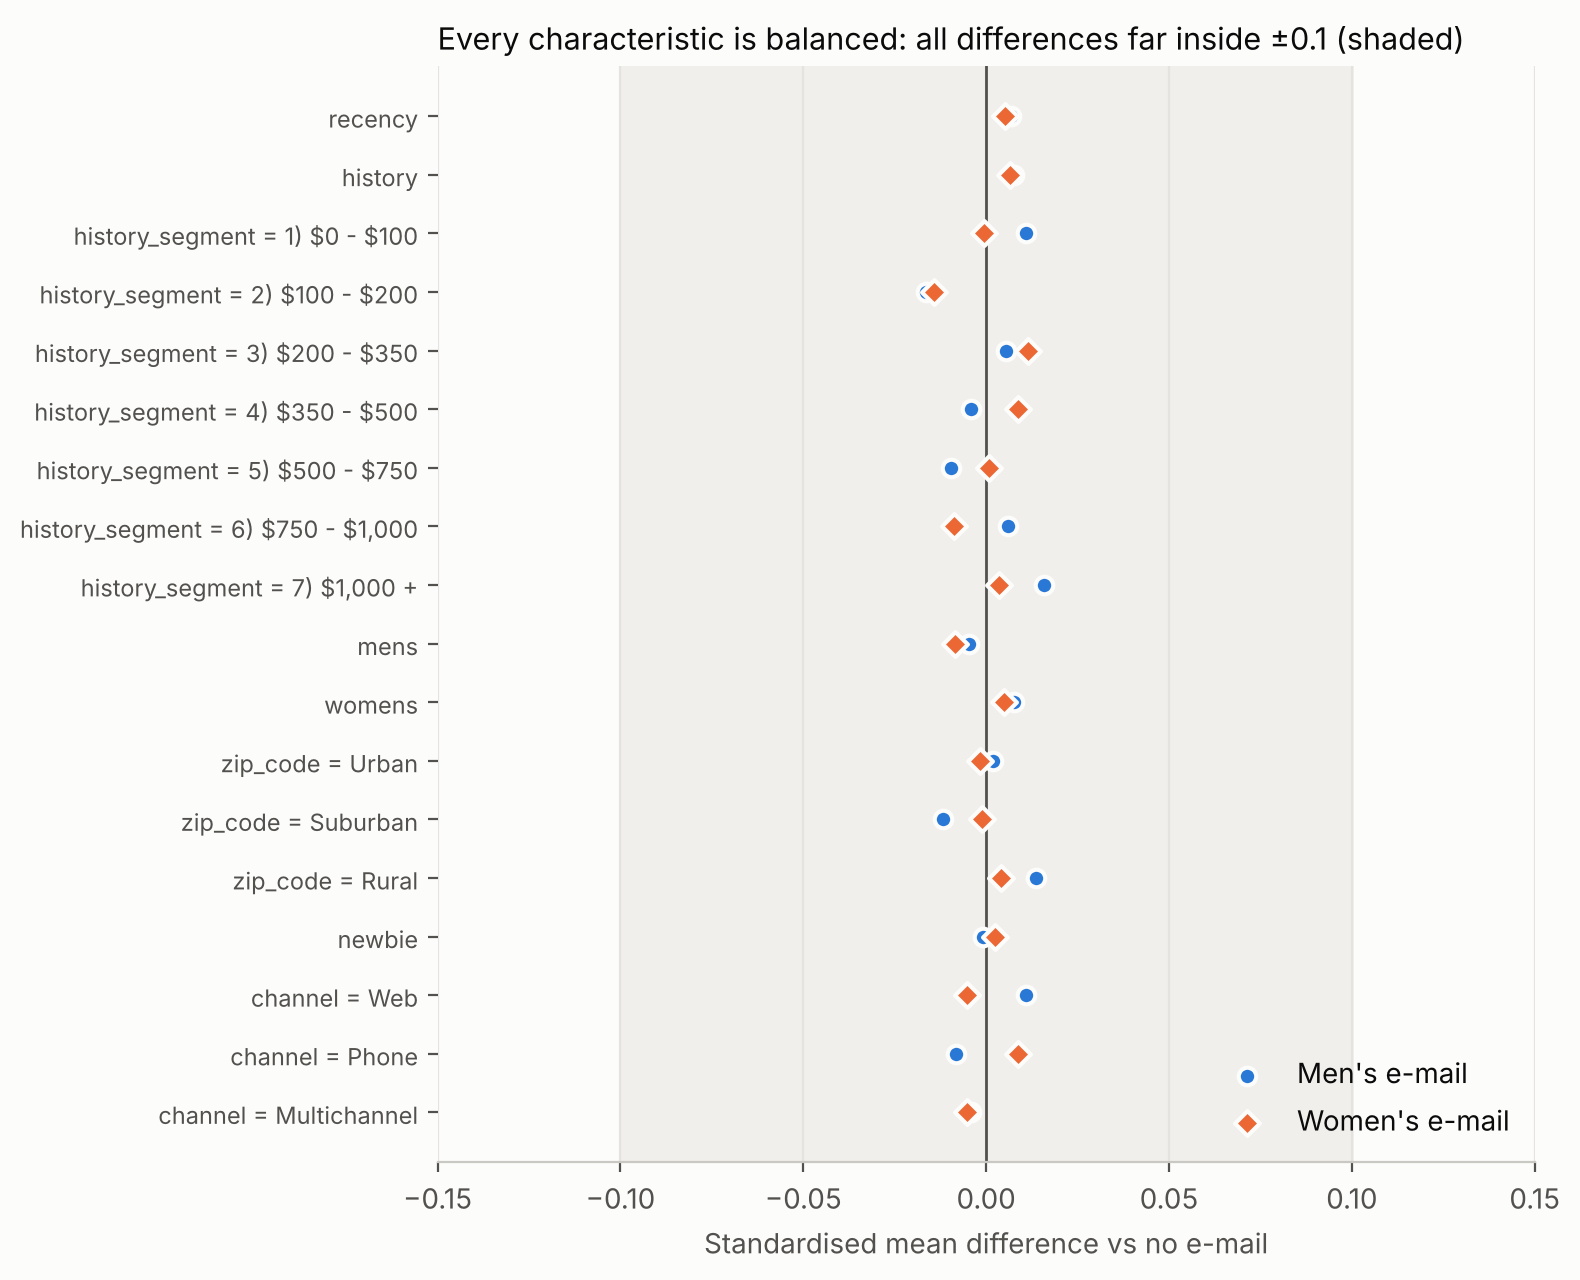

In [13]:
# figure: balance
INK, INK_2, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"
SERIES = {"SMD Mens E-Mail": ("#2a78d6", "o", "Men's e-mail"), "SMD Womens E-Mail": ("#eb6834", "D", "Women's e-mail")}

labels = [label.replace("$", r"\$") for label in balance.index][::-1]
y = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(8, 6.5), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.axvspan(-0.1, 0.1, color="#f0efec", zorder=0)
ax.axvline(0, color=INK_2, linewidth=1)
for col, (color, marker, name) in SERIES.items():
    ax.scatter(balance[col].iloc[::-1], y, color=color, marker=marker, s=40, zorder=3,
               edgecolor=SURFACE, linewidth=1.5, label=name)
ax.set_yticks(y, labels, fontsize=8.5, color=INK_2)
ax.set_xlim(-0.15, 0.15)
ax.set_xlabel("Standardised mean difference vs no e-mail", color=INK_2)
ax.set_title("Every characteristic is balanced: all differences far inside ±0.1 (shaded)",
             loc="left", color=INK, fontsize=11)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.tick_params(colors=INK_2)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#c9c8c3")
ax.legend(frameon=False, loc="lower right", labelcolor=INK)
plt.tight_layout()
plt.show()

In [14]:
print(f"Largest |SMD|: {balance[smd_cols].abs().max().max():.3f} "
      f"({balance[smd_cols].abs().max(axis=1).idxmax()})")

Largest |SMD|: 0.016 (history_segment = 2) $100 - $200)


## 6. Significance tests per covariate, and the trap inside them

It is common to also run a significance test for each covariate.

In [15]:
tests = covariate_tests(df, "segment", PRE_TREATMENT, CATEGORICAL)
tests.style.format({"p_value": "{:.3f}", "p_holm": "{:.3f}"})

,test,p_value,p_holm
covariate,,,
recency,Kruskal-Wallis,0.794,1.000
history,Kruskal-Wallis,0.667,1.000
history_segment,chi-square,0.358,1.000
mens,chi-square,0.672,1.000
womens,chi-square,0.729,1.000
zip_code,chi-square,0.579,1.000
newbie,chi-square,0.934,1.000
channel,chi-square,0.458,1.000


All p-values are well above 0.05. But suppose one had come out at 0.03. Would that mean the randomisation failed?

**No.** With eight tests, the chance that *at least one* is below 0.05 purely by luck is large. We can measure it with a **placebo experiment**: shuffle the group labels at random (so any imbalance is pure chance by construction) and rerun all eight tests, many times.

In [16]:
rng = np.random.default_rng(2008)
N_PLACEBO = 300
min_p = []
placebo = df[PRE_TREATMENT].copy()
for _ in range(N_PLACEBO):
    placebo["group"] = rng.permutation(df["segment"].to_numpy())
    min_p.append(covariate_tests(placebo, "group", PRE_TREATMENT, CATEGORICAL)["p_value"].min())
min_p = np.array(min_p)
print(f"Placebo experiments with at least one covariate at p < 0.05: {(min_p < 0.05).mean():.0%}")
print(f"Same after the Holm adjustment (smallest p x 8 < 0.05):        {(np.minimum(min_p * 8, 1) < 0.05).mean():.0%}")

Placebo experiments with at least one covariate at p < 0.05: 27%
Same after the Holm adjustment (smallest p x 8 < 0.05):        4%


In roughly a quarter of perfectly random assignments, at least one covariate looks "significantly" imbalanced. After the Holm adjustment that drops to about the intended 5%. That is why the go/no-go relies on the **size** of imbalances (SMD), on **adjusted** p-values, and on a single **joint** test, never on whether one covariate happens to cross 0.05.

## 7. Joint balance test

One test per comparison: can all the covariates *together* predict whether a customer was in the email group or the holdout? If assignment was random, they should carry no information. (`history_segment` is left out because it is just a bucketed copy of `history`.)

In [17]:
joint_covariates = [c for c in PRE_TREATMENT if c != "history_segment"]
rows = []
for treatment in ["Mens E-Mail", "Womens E-Mail"]:
    r = joint_balance_test(df, "segment", CONTROL, treatment, joint_covariates, ["zip_code", "channel"])
    rows.append({"comparison": f"{treatment} vs {CONTROL}", "LR statistic": r.lr_stat, "df": r.df, "p_value": r.p_value})
pd.DataFrame(rows).set_index("comparison").style.format({"LR statistic": "{:.2f}", "p_value": "{:.2f}"})

,LR statistic,df,p_value
comparison,,,
Mens E-Mail vs No E-Mail,6.35,9,0.70
Womens E-Mail vs No E-Mail,3.86,9,0.92


## 8. Decision

| Check | Result | Verdict |
|---|---|---|
| Columns and values | As specified; no missing values | Pass |
| Labels | One typo, fixed | Pass |
| Duplicates | Identical customers, not repeated records (no ID to prove it) | Pass with caveat |
| Sample ratio | p = 0.90 | Pass |
| Balance, size | Largest \|SMD\| 0.016, threshold 0.1 | Pass |
| Balance, per covariate | All p > 0.3 | Pass |
| Balance, joint | p = 0.70 (men's), 0.92 (women's) | Pass |

**GO.** The results can be read as pre-registered. Two caveats travel into the readout: purchases appear to be **online only**, and **spend is capped at $499**.

## 9. Try it yourself

**a) Break the experiment on purpose.** Suppose emails to customers with a bad address bounced and those customers were silently dropped from the email groups only. Simulate it: remove a random 3% of customers from each email group, then rerun the sample-ratio check. Does it catch the problem? Now remove only newbies from the email groups. Which checks catch that?

**b) A borderline SRM.** The check gives p = 0.0004. The product manager says "it's only a few hundred customers, let's just read the results". What do you answer, and what do you investigate first?

**c) The online-only finding.** Write two sentences for the readout explaining to the CFO what "online purchases only" means for how to interpret the results.

In [18]:
# a) Your code here, for example:
# keep = ~((df["arm"] != "control") & (rng.random(len(df)) < 0.03))
# srm_test(df.loc[keep, "segment"].value_counts())

## Summary

The data is usable after one label fix, the randomisation worked on every check, and two measurement caveats are recorded. The [validation report](../docs/company_documents/ch3_validation_report.md) gives the go.

**Next, chapter 4a:** the readout, where we finally compare outcomes between the groups.